# Framingham CHD risk — data, imbalance, and the threshold nobody chose

A short, executed walkthrough of the three things that decide what this model is
worth:

1. **The base rate.** 15% of participants develop CHD, so accuracy is close to
   useless as a headline.
2. **Calibration.** `class_weight="balanced"` triples the predicted probabilities
   without changing the ranking at all.
3. **The decision threshold.** The 0.5 default catches almost nobody.

Every number below is computed here, from the raw CSV, with the same pipeline the
scripts use. Nothing is quoted from memory.

In [1]:
import pathlib, sys
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
sys.path.insert(0, str(ROOT))
print("repository root:", ROOT)

repository root: /home/heisenberg/portfolio-rework/repos/heart-attack-risk-prediction


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

from src.data import load_dataset, missingness_table
from src.evaluate import (
    calibration_summary,
    cross_validate_models,
    majority_baseline,
    threshold_table,
)
from src.models import get_models

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

X, y = load_dataset()
print(f"loaded {len(X):,} participants x {X.shape[1]} features")
print(f"positive class: {int(y.sum())} ({y.mean():.2%})")

loaded 4,238 participants x 15 features
positive class: 644 (15.20%)


## 1. The data, and where it is missing

The loader returns the frame **with missing values intact**. Imputation happens
inside the model pipeline, on training folds only.

In [3]:
missingness_table(X).style.format({"pct_missing": "{:.2f}%"}).set_caption(
    "missing values by column"
)

,missing,pct_missing
glucose,388,9.16%
education,105,2.48%
BPMeds,53,1.25%
totChol,50,1.18%
cigsPerDay,29,0.68%
BMI,19,0.45%
heartRate,1,0.02%


## 2. The number that decides everything

Before looking at any model, look at what a model that learns nothing scores.

positive rate                        0.1520
accuracy of always predicting 'no'   0.8480
recall of always predicting 'no'     0.0000
PR-AUC of a constant predictor       0.1520


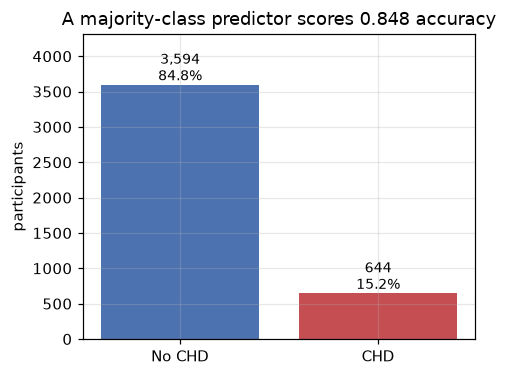

In [4]:
baseline = majority_baseline(y)
print(f"positive rate                        {baseline['positive_rate']:.4f}")
print(f"accuracy of always predicting 'no'   {baseline['accuracy_if_always_majority']:.4f}")
print(f"recall of always predicting 'no'     {baseline['recall_on_positives']:.4f}")
print(f"PR-AUC of a constant predictor       {baseline['pr_auc_of_constant']:.4f}")

fig, ax = plt.subplots(figsize=(4.6, 3.6))
counts = y.value_counts().sort_index()
bars = ax.bar(["No CHD", "CHD"], counts.values, color=["#4C72B0", "#C44E52"])
for bar, c in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, c, f"{c:,}\n{c / len(y):.1%}",
            ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, counts.max() * 1.2)
ax.set_ylabel("participants")
ax.set_title("A majority-class predictor scores 0.848 accuracy")
plt.show()

## 3. Cross-validated comparison

Three models are enough to make the point: the majority baseline, the original
notebook's logistic regression, and the same model with `class_weight="balanced"`.
Preprocessing (median / most-frequent imputation, then scaling) is re-fitted
inside every fold.

In [5]:
all_models = get_models()
models = {k: all_models[k] for k in [
    "Dummy (majority class)",
    "Logistic Regression",
    "Logistic Regression (balanced)",
]}

cv = cross_validate_models(models, X, y, n_splits=5)
display = pd.DataFrame({
    "model": cv["model"],
    "accuracy": cv.apply(lambda r: f"{r.accuracy_mean:.4f} ± {r.accuracy_std:.4f}", axis=1),
    "precision": cv.apply(lambda r: f"{r.precision_mean:.4f} ± {r.precision_std:.4f}", axis=1),
    "recall": cv.apply(lambda r: f"{r.recall_mean:.4f} ± {r.recall_std:.4f}", axis=1),
    "f1": cv.apply(lambda r: f"{r.f1_mean:.4f} ± {r.f1_std:.4f}", axis=1),
    "roc_auc": cv.apply(lambda r: f"{r.roc_auc_mean:.4f} ± {r.roc_auc_std:.4f}", axis=1),
    "pr_auc": cv.apply(lambda r: f"{r.pr_auc_mean:.4f} ± {r.pr_auc_std:.4f}", axis=1),
})
display

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Dummy (majority class),0.8480 ± 0.0005,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.1520 ± 0.0005
1,Logistic Regression,0.8551 ± 0.0040,0.7099 ± 0.1240,0.0807 ± 0.0249,0.1440 ± 0.0403,0.7250 ± 0.0201,0.3466 ± 0.0341
2,Logistic Regression (balanced),0.6737 ± 0.0238,0.2701 ± 0.0191,0.6708 ± 0.0403,0.3849 ± 0.0234,0.7250 ± 0.0203,0.3446 ± 0.0342


**Read the `recall` column.** The logistic regression has the best accuracy in the
table (0.8551) and catches **8%** of the people who go on to develop CHD. The
balanced variant catches 67% and its accuracy drops to 0.67 — but note that its
ROC-AUC is *identical*. Something other than discrimination is changing.

Below, out-of-fold probabilities: every participant scored by a model that never
saw them.

In [6]:
from src.evaluate import out_of_fold_probabilities

oof = pd.DataFrame({"y_true": np.asarray(y)})
for name, pipe in models.items():
    oof[name] = out_of_fold_probabilities(pipe, X, y, n_splits=5)

calib = calibration_summary(
    oof["y_true"].to_numpy(),
    {c: oof[c].to_numpy() for c in models},
    reference_model="Logistic Regression",
)
calib.style.format({
    "observed_rate": "{:.4f}", "mean_predicted": "{:.4f}",
    "calibration_ratio": "{:.3f}", "brier": "{:.4f}",
    "ece_quantile_10": "{:.4f}", "spearman_vs_reference": "{:.4f}",
}).set_caption("calibration, out-of-fold")

,model,observed_rate,mean_predicted,calibration_ratio,brier,ece_quantile_10,spearman_vs_reference
0,Dummy (majority class),0.1520,0.1520,1.000,0.1289,0.0004,-0.0471
1,Logistic Regression,0.1520,0.1518,0.999,0.1166,0.0152,1.0000
2,Logistic Regression (balanced),0.1520,0.4422,2.910,0.2102,0.2902,0.9982


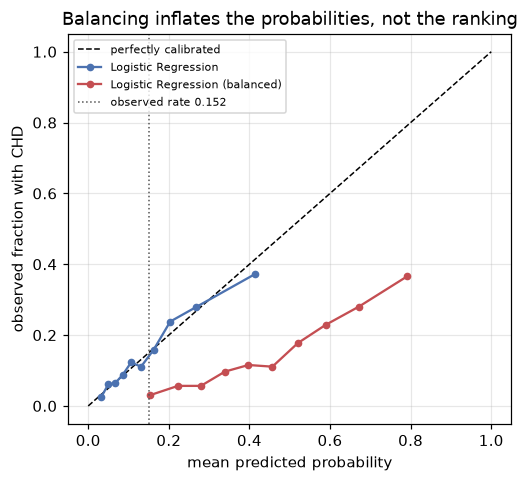

In [7]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
for name, color in [("Logistic Regression", "#4C72B0"),
                    ("Logistic Regression (balanced)", "#C44E52")]:
    frac, mean_pred = calibration_curve(oof["y_true"], oof[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, "o-", color=color, ms=4, lw=1.5, label=name)
ax.axvline(oof["y_true"].mean(), color="#555555", ls=":", lw=1, label="observed rate 0.152")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("observed fraction with CHD")
ax.set_title("Balancing inflates the probabilities, not the ranking")
ax.legend(fontsize=7.5, loc="upper left")
plt.show()

The Spearman column above is ~0.998: the balanced model puts participants in
almost exactly the same order. It multiplies every probability by ~2.9. That
inflation is the *entire* reason it catches more cases at a fixed 0.5 cut-off —
and the same effect is available for free, and reversibly, by moving the
threshold.

## 4. The threshold nobody chose

Using the well-calibrated model's out-of-fold probabilities.

In [8]:
proba = oof["Logistic Regression"].to_numpy()
y_true = oof["y_true"].to_numpy()
table = threshold_table(y_true, proba)
table.style.format({
    "threshold": "{:.2f}", "precision": "{:.3f}", "recall": "{:.3f}",
    "f1": "{:.3f}", "flagged_rate": "{:.1%}",
}).set_caption("precision / recall by decision threshold")

,threshold,precision,recall,f1,flagged_rate,tp,fp,fn,tn
0,0.05,0.172,0.960,0.292,84.8%,618,2977,26,617
1,0.10,0.218,0.831,0.345,57.9%,535,1918,109,1676
2,0.15,0.267,0.671,0.382,38.2%,432,1188,212,2406
3,0.20,0.308,0.519,0.386,25.6%,334,752,310,2842
4,0.25,0.337,0.379,0.356,17.1%,244,481,400,3113
5,0.30,0.352,0.256,0.296,11.1%,165,304,479,3290
6,0.35,0.415,0.179,0.250,6.5%,115,162,529,3432
7,0.40,0.462,0.132,0.205,4.3%,85,99,559,3495
8,0.45,0.561,0.099,0.169,2.7%,64,50,580,3544
9,0.50,0.703,0.081,0.145,1.7%,52,22,592,3572


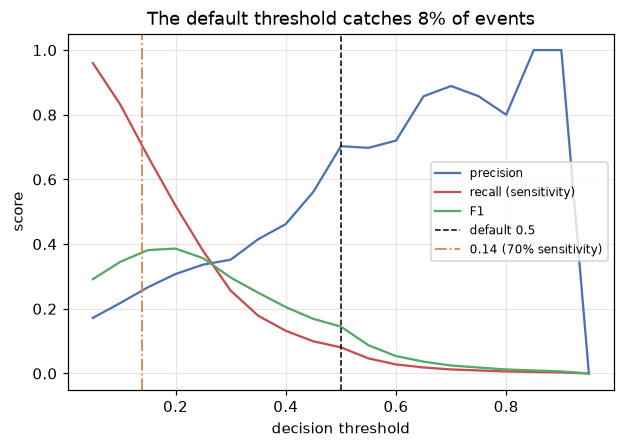

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(table.threshold, table.precision, label="precision", color="#4C72B0")
ax.plot(table.threshold, table.recall, label="recall (sensitivity)", color="#C44E52")
ax.plot(table.threshold, table.f1, label="F1", color="#55A868")
ax.axvline(0.5, color="k", ls="--", lw=1, label="default 0.5")
ax.axvline(0.14, color="#DD8452", ls="-.", lw=1.2, label="0.14 (70% sensitivity)")
ax.set_xlabel("decision threshold")
ax.set_ylabel("score")
ax.set_title("The default threshold catches 8% of events")
ax.legend(fontsize=8)
plt.show()

In [10]:
default = table.loc[(table.threshold - 0.5).abs().idxmin()]
sens70 = table.loc[(table.threshold - 0.14).abs().idxmin()]
print(f"threshold 0.50: recall {default.recall:.3f}, flags {default.flagged_rate:.1%} of everyone,"
      f" catches {int(default.tp)} of {int(y_true.sum())} events")
print(f"threshold 0.14: recall {sens70.recall:.3f}, flags {sens70.flagged_rate:.1%} of everyone,"
      f" catches {int(sens70.tp)} of {int(y_true.sum())} events,"
      f" {int(sens70.fp)} of those flags are false alarms")

threshold 0.50: recall 0.081, flags 1.7% of everyone, catches 52 of 644 events
threshold 0.14: recall 0.671, flags 38.2% of everyone, catches 432 of 644 events, 1188 of those flags are false alarms


## What this notebook concludes

- **Accuracy is the wrong headline here.** A predictor that learns nothing scores
  0.848; the best model scores 0.8551 while missing 92% of events at the default
  threshold.
- **Discrimination is modest.** ROC-AUC ≈ 0.725, PR-AUC ≈ 0.347 against a
  no-skill 0.152.
- **Imbalance weighting is a relabelling.** `class_weight="balanced"` leaves the
  ranking unchanged (Spearman 0.998) and triples the predicted probabilities,
  costing a doubling of the Brier score (0.117 → 0.210).
- **The threshold is the real decision.** Reaching 70% sensitivity means flagging
  about 42% of the cohort, three quarters of them wrongly.

This is a risk-ranking tool, not a referral rule. The full analysis, the leakage
audit of the original notebook, and the tests are in the repository.